# **1. 시퀀스 데이터**
시퀀스 데이터(Sequence Data)는 시간적 혹은 순서적 관계가 중요한 데이터를 말합니다. 일반적인 데이터가 순서와 무관하게 독립적으로 다뤄지는 것과 달리, 시퀀스 데이터는 각 요소가 특정 순서에 따라 나열되어 있고 앞뒤 맥락이 의미를 가집니다. 대표적인 예로는 자연어 문장(단어의 순서 중요), 시계열 데이터(주가, 날씨 변화), 음성 신호(시간에 따른 파형), 영상 프레임(연속된 이미지) 등이 있습니다. 따라서 시퀀스 데이터는 단순한 값들의 모음이 아니라, 순서와 맥락이 포함된 정보 구조로 이해하는 것이 핵심입니다.

# **2. RNN**
RNN(Recurrent Neural Network, 순환 신경망)은 시계열 데이터나 연속적인 데이터를 다룰 때 사용되는 인공 신경망으로, 일반적인 신경망(CNN, MLP 등)이 입력을 한 번 처리하고 끝나는 것과 달리, 과거의 정보를 기억하며 다음 계산에 반영하는 특징이 있습니다. 일반적인 신경망은 현재 입력만 보고 예측하지만, 시계열 데이터나 자연어처럼 이전 정보가 중요한 경우에는 적절하지 않기 때문에 RNN이 필요합니다. RNN은 기존 신경망과 달리 자신의 출력을 다시 입력으로 사용하여 과거 정보를 기억하는 구조를 가지며, 이를 통해 시계열 데이터의 패턴을 학습할 수 있습니다.  그러나 일반적인 RNN은 장기 의존성(Long-Term Dependency) 문제로 인해 학습이 어려울 수 있으며, 이를 해결하기 위해 장단기 메모리(Long Short-Term Memory, LSTM)나 게이트 순환 유닛(Gated Recurrent Unit, GRU)과 같은 변형 모델이 개발되었습니다. 

![RNN1](./images/RNN1.png)
![RNN2](./images/RNN2.png)



```
h_t = tanh(W_xh x_t + Whh h_(t-1) + b)
```

- x_t = 현재 시점 입력값
- h_(t-1) = 이전 시점까지의 기억(가중치)
- h_t: 현재 입력까지 반영한 새로운 기억(가중치)
- W_xh, W_hh: 학습되는 가중치
- tanh: 값을 -1 ~ 1 범위로 압축하는 활성화 함수

> 일반적인 MLP는 입력하나를 받아 출력 하나를 만들고 계산이 끝남. 반면 RNN은 현재 입력 x_t와 이전 기억 h_(t-1)을 함께 사용해서 새로운 기억 h_t를 만든다.

> 매 시점마다 서로 다른 RNN을 사용하는 것이 아니라 같은 RNN Cell의 가중치를 시간축 전체에서 공유. 그래서 길이가 다른 시퀀스도 같은 원리로 처리할 수 있음

> 장기의존성을 개선해서 만든게 LSTM, GRU같은 모델이다. (장기의존성은 RNN의 단점)

```
[batch_size, sequence_length, input_size]
예를들어 [32, 20, 10]
```
- 10: 하루를 표현하는 feature 수
- 20: 샘플 하나에서 연속해서 보는 날짜 수
- 32: 한 번에 처리하는 샘플(시퀀스) 수 (20일씩 32개가 묶여있다.)

> 32명분의 묶음 * 각 묶음당 20일 * 하루당 10개 숫자
> RNN은 첫째 날을 처리해 h1을 만들고, 둘째 날에는 둘째 날 입력과 h1을 같이 사용해 h2를 만듦 ... 이 과정이 마지막 날까지 반복

# **3. RNN을 이용한 KOSPI 예측**

- 최근 20거래일의 정보를 하나의 입력 시퀀스로 만들어 그 다음 거래일의 종가(Close)를 예측
```
1일차 입력 + 초기 기억(0) > 1일차 hidden state 
2일차 입력 + 1일차 hidden state > 2일차 hidden state
3일차 입력 + 2일차 hidden sstate > 3일차 hidden state
...
20일차 입력 + 19일차 hidden state > 20일차 hidden state
20일차 hidden state > Linear Layer > 21일차 종가 예측
```
- 날짜를 t라고 하면 입력은 t-19 ~ t거래일까지의 정보이며, 정답은 t+ 거래일의 Close임 

### hidden state
- RNN의 작업 메모리
- 현재 시점까지 본 입력 중 앞으로의 계산에 필요하다고 모델이 판단한 정보를 숫자 벡터로 압축해 둔 것
- 예) hidden_size=64라면 각 시점마다 RNN은 64개의 숫자로 된 기억을 만듦. 이 64개의 값에 무엇을 저장할지는 사람이 지정하지 않고 학습 과정에서 모델이 결정
    - input_size: 한 시점에 입력되는 feature 개수
    - sequence_length: 연속해서 몇 시점을 볼 것인지
    - hidden_size: 내부 기억을 몇 개의 숫자로 표현할 것인지
    - num_layers: RNN을 몇 층으로 쌓을 것인지

### RNN이 tanh를 사용하는 이유
- 현재 입력과 이전 hidden state를 합산한 뒤 tanh를 통과시켜 새로운 hidden state를 만듦
- tanh는 출력 범위 -1 ~ 1로 제한하므로 반복 계산에서 값이 무작정 커지는 것을 어느 정도 억제함

> RNN은 가까운 과거의 패턴을 학습하는 데는 유용하지만, 수십~수백 시점 전의 정보를 끝까지 안정적으로 유지하기 어려움. 같은 가중치를 반복 적용하면서 역전파하기 때문에 긴 시퀀스에서 기울기 소실/폭주 문제가 나타나기 쉽다

In [1]:
import copy
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

In [2]:
if torch.cuda.is_available():
    DEVICE = torch.device('cuda')
elif torch.backends.mps.is_available():
    DEVICE = torch.device('mps')
elif torch.xpu.is_available():
    DEVICE = torch.device('xpu')
else:
    DEVICE = torch.device('cpu')

print(DEVICE)

mps


In [3]:
SEED = 2026
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

In [4]:
# Open: 시가. 그날 장이 시작됐을 때의 가격
# High: 고가. 그날 거래 중 기록한 가장 높은 가격
# Low: 저가. 그날 거래 중 기록한 가장 낮은 가격
# Close: 종가. 그날 장이 끝났을 때의 가격
# Adj Close: 수정 종가. 배당, 주식분할 등의 영향을 반영해서 조정한 종가
# Volume: 거래량. 그날 거래된 주식의 양
df = pd.read_csv("./data/kospi.csv")
df

,Date,Open,High,Low,Close,Adj Close,Volume
0,04/01/2000,1028.329956,1066.180054,1016.590027,1059.040039,1059.040039,19589800.0
1,05/01/2000,1006.869995,1026.520020,984.049988,986.309998,986.309998,25769600.0
2,06/01/2000,1013.950012,1014.900024,953.500000,960.789978,960.789978,20352300.0
3,07/01/2000,949.169983,970.159973,930.840027,948.650024,948.650024,21566400.0
4,10/01/2000,979.669983,994.940002,974.820007,987.239990,987.239990,24017500.0
...,...,...,...,...,...,...,...
4508,16/01/2018,2504.159912,2524.550049,2498.550049,2521.739990,2521.739990,341600.0
4509,17/01/2018,2517.189941,2521.969971,2506.489990,2515.429932,2515.429932,336700.0
4510,18/01/2018,2527.669922,2532.080078,2512.689941,2515.810059,2515.810059,333100.0
4511,19/01/2018,2519.669922,2524.330078,2513.090088,2520.260010,2520.260010,351800.0


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4513 entries, 0 to 4512
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Date       4513 non-null   str    
 1   Open       4452 non-null   float64
 2   High       4452 non-null   float64
 3   Low        4452 non-null   float64
 4   Close      4452 non-null   float64
 5   Adj Close  4452 non-null   float64
 6   Volume     4452 non-null   float64
dtypes: float64(6), str(1)
memory usage: 246.9 KB


In [6]:
# dayfirst=True 문자열 날짜를 datetime으로 변환함. 원본 날짜가 일/월/년 형식이라는 가정으로 변환
df['Date'] = pd.to_datetime(df['Date'], dayfirst=True, errors='coerce')
df


,Date,Open,High,Low,Close,Adj Close,Volume
0,2000-01-04,1028.329956,1066.180054,1016.590027,1059.040039,1059.040039,19589800.0
1,2000-01-05,1006.869995,1026.520020,984.049988,986.309998,986.309998,25769600.0
2,2000-01-06,1013.950012,1014.900024,953.500000,960.789978,960.789978,20352300.0
3,2000-01-07,949.169983,970.159973,930.840027,948.650024,948.650024,21566400.0
4,2000-01-10,979.669983,994.940002,974.820007,987.239990,987.239990,24017500.0
...,...,...,...,...,...,...,...
4508,2018-01-16,2504.159912,2524.550049,2498.550049,2521.739990,2521.739990,341600.0
4509,2018-01-17,2517.189941,2521.969971,2506.489990,2515.429932,2515.429932,336700.0
4510,2018-01-18,2527.669922,2532.080078,2512.689941,2515.810059,2515.810059,333100.0
4511,2018-01-19,2519.669922,2524.330078,2513.090088,2520.260010,2520.260010,351800.0


In [7]:
numeric_cols = ['Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume']
for col in numeric_cols:
    if col in df.columns:
        # 변환할 수 없는 값은 NaN으로 처리
        df[col] = pd.to_numeric(df[col], errors='coerce')

In [8]:
required_cols = ['Date', 'Open', 'High', 'Low', 'Close']
df_copy = df.dropna(subset=required_cols).copy()

In [9]:
df_copy = df_copy.sort_values("Date").reset_index(drop=True)
print('데이터 기간: ', df_copy['Date'].min(), " ~ ", df_copy['Date'].max())
print('전체 행 수: ', len(df_copy))

데이터 기간:  2000-01-04 00:00:00  ~  2018-01-22 00:00:00
전체 행 수:  4452


In [10]:
df_copy.info()

<class 'pandas.DataFrame'>
RangeIndex: 4452 entries, 0 to 4451
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   Date       4452 non-null   datetime64[us]
 1   Open       4452 non-null   float64       
 2   High       4452 non-null   float64       
 3   Low        4452 non-null   float64       
 4   Close      4452 non-null   float64       
 5   Adj Close  4452 non-null   float64       
 6   Volume     4452 non-null   float64       
dtypes: datetime64[us](1), float64(6)
memory usage: 243.6 KB


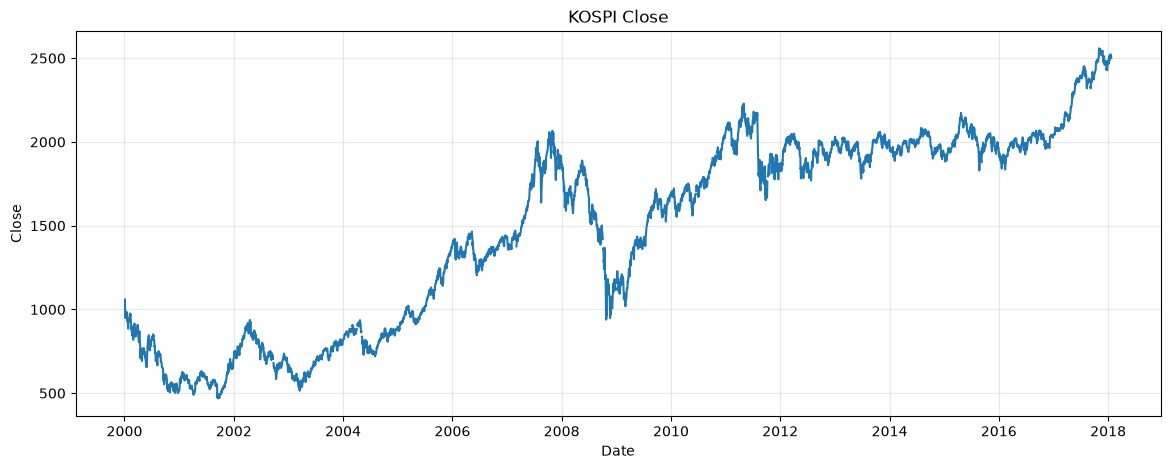

In [11]:
plt.figure(figsize=(14, 5))
plt.plot(df["Date"], df["Close"])
plt.title("KOSPI Close")
plt.xlabel("Date")
plt.ylabel("Close")
plt.grid(alpha=0.3)
plt.show()

### Feature Engineering
RNN에 종가만 넣을 수도 있지만, 하루의 가격 구조와 최근 추세를 더 표현하기 위해 파생변수를 추가
- Open, High, Low, Close: 당일 가격 정보
- Return_1d: 전 거래일 대비 종가 수익률
- Range_pct: 당일 고가-저가 폭을 종가로 나눈 값
- OC_pct: 시가 대비 종가 변화율
- MA5_ratio: 현재 종가 / 최근 5일 이동평균
- MA20_ratio: 현재 종가 / 최근 20일 이동평균
- Volatility_10: 최근 10일 수익률의 표준편차

> 정답은 shift(-1)을 사용한 다음 거래일 종가
> 예를들면, 현재 행이 t일이면 Feature: t일까지 계산 가능한 정보, Target: t+1까지 거래일의 Close

In [12]:
data = df_copy.copy()

data["Return_1d"] = data["Close"].pct_change()
data["Range_pct"] = (data["High"] - data["Low"]) / data["Close"]
data["OC_pct"] = (data["Close"] - data["Open"]) / data["Open"]

data["MA5"] = data["Close"].rolling(5).mean()
data["MA20"] = data["Close"].rolling(20).mean()

data["MA5_ratio"] = data["Close"] / data["MA5"]
data["MA20_ratio"] = data["Close"] / data["MA20"]

data["Volatility_10"] = data["Return_1d"].rolling(10).std()

# 다음 거래일 종가와 날짜를 정답으로 사용합니다.
data["Target_Close"] = data["Close"].shift(-1)
data["Target_Date"] = data["Date"].shift(-1)

FEATURES = [
    "Open",
    "High",
    "Low",
    "Close",
    "Return_1d",
    "Range_pct",
    "OC_pct",
    "MA5_ratio",
    "MA20_ratio",
    "Volatility_10",
]

# rolling으로 생긴 앞부분 NaN과 마지막 target NaN을 제거합니다.
data = data.dropna(subset=FEATURES + ["Target_Close", "Target_Date"]).reset_index(drop=True)

print("사용할 Feature 개수:", len(FEATURES))
print("정제 후 데이터 수:", len(data))
data[["Date"] + FEATURES + ["Target_Date", "Target_Close"]].head()

사용할 Feature 개수: 10
정제 후 데이터 수: 4432


,Date,Open,High,Low,Close,Return_1d,Range_pct,OC_pct,MA5_ratio,MA20_ratio,Volatility_10,Target_Date,Target_Close
0,2000-01-31,924.830017,948.840027,922.919983,943.880005,0.002347,0.027461,0.020598,1.032344,0.990929,0.025395,2000-02-01,928.750000
1,2000-02-01,955.440002,959.309998,923.520020,928.750000,-0.016030,0.038536,-0.027935,1.007524,0.981760,0.025668,2000-02-02,943.590027
2,2000-02-02,929.690002,950.130005,923.400024,943.590027,0.015978,0.028328,0.014951,1.010891,0.999704,0.022495,2000-02-03,950.219971
3,2000-02-03,950.260010,959.000000,934.109985,950.219971,0.007026,0.026194,-0.000042,1.009131,1.007292,0.022477,2000-02-07,973.130005
4,2000-02-07,953.229980,982.030029,951.309998,973.130005,0.024110,0.031568,0.020876,1.026602,1.030241,0.022042,2000-02-08,961.219971


### Train/Validation/Test 분리
- 시계열에서 랜덤 분할을 하면 미래 시점의 데이터가 Train에 들어가고 과거 시점이 Test에 들어가는 비현실적인 평가가 될 수 있음
- 앞 70%를 Train, 다음 15%를 Validation, 마지막 15% Test로 나눔

In [13]:
n = len(data)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

print("Train rows :", train_end)
print("Valid rows :", val_end - train_end)
print("Test rows  :", n - val_end)

print()
print("Train target 기간:",
    data.loc[0, "Target_Date"], "~",
    data.loc[train_end - 1, "Target_Date"])

print("Valid target 기간:",
    data.loc[train_end, "Target_Date"], "~",
    data.loc[val_end - 1, "Target_Date"])

print("Test target 기간 :",
    data.loc[val_end, "Target_Date"], "~",
    data.loc[n - 1, "Target_Date"])

Train rows : 3102
Valid rows : 665
Test rows  : 665

Train target 기간: 2000-02-01 00:00:00 ~ 2012-08-20 00:00:00
Valid target 기간: 2012-08-21 00:00:00 ~ 2015-05-04 00:00:00
Test target 기간 : 2015-05-06 00:00:00 ~ 2018-01-22 00:00:00


### Scaling
- Open/High/Low/Close는 단위 수백 또는 수천 단위이고 수익률은 0에 가까운 소수이므로 그대로 학습하면 feature별 숫자 크기 차이가 큼
- StandardScaler를 사용하여 각 feature를 대략 평균 0, 표준편차를 1이 되도록 변환
- Scaler의 평균과 표준편차를 Train 데이터만 계산 > Validation/Test까지 포함해 fit()하면 미래 데이터의 통계량을 미리 아는 데이터 누수가 됨

In [14]:
scaler_x = StandardScaler()
scaler_y = StandardScaler()

# fit: 기준을 계산해서 기억
scaler_x.fit(data.loc[:train_end - 1, FEATURES])
scaler_y.fit(data.loc[:train_end - 1, ['Target_Close']])

# transform: 기억한 기준으로 실제 데이터를 변환
# 한꺼번에 처리 > fit_transform()
X_all = scaler_x.transform(data[FEATURES]).astype(np.float32)
y_all = scaler_y.transform(data[['Target_Close']]).astype(np.float32)

print('X_all shape: ', X_all.shape)
print('y_all shape: ', y_all.shape)

X_all shape:  (4432, 10)
y_all shape:  (4432, 1)


### 시퀀스 만들기
- RNN은 한 행씩 독립적으로 보는 대신 연속된 여러 행을 하나의 샘플로 받음
- 예) SEQUENCE_LENGTH=20이면 최근 20거래일을 하나의 window(하나의 시퀀스 단위)로 만듦
    - i=19라면 입력은 0~19번 행이고 정답 y[19]는 19번 행의 다음 거래일 종가
    - i=20이면 입력은 0~20번 행이 됨 > window가 하루씩 이동

> 전체 시계열에서 먼저 window를 만든 다음 정답이 속한 시점 기준으로 Train/Val/Test를 나눔. Validation/Test의 첫 예측에서도 직전 과거 구간을 입력 history로 사용할 수 있음

In [15]:
SEQUENCE_LENGTH = 20

def make_sequence(X, y, sequence_length):
    X_seq = []
    y_seq = []
    target_indicies = []
    
    for i in range(sequence_length - 1, len(X)):
        start = i - sequence_length + 1
        X_seq.append(X[start:i+1])
        y_seq.append(y[i])
        target_indicies.append(i)
    
    return (np.asarray(X_seq, dtype=np.float32), np.asarray(y_seq, dtype=np.float32), np.asarray(target_indicies, dtype=np.int64))

In [16]:
X_seq, y_seq, target_indices = make_sequence(X_all, y_all, SEQUENCE_LENGTH)
print('전체 sequence shape: ', X_seq.shape)
print('전체 target shape: ', y_seq.shape)
print('target index shape: ', target_indices.shape)

전체 sequence shape:  (4413, 20, 10)
전체 target shape:  (4413, 1)
target index shape:  (4413,)


### Dataset과 DataLoader
- Dataset은 X와 y를 PyTorch Tensor로 보관하고, DataLoader는 mini-batch로 나누어 모델에 데이터를 공급
- shuffle=True 는 배치 순서만 섞기 때문에 20 window 내부 날짜 순서를 섞는 것이 아님 
- 예) [1~20일], [2~21일], [3~22일] 이라는 window가 있다면 이 window 가 모델에 들어가는 순서는 바뀔 수 있지만 각 window 내부에 날짜 순서는 그대로임


In [17]:
train_mask = target_indices < train_end
val_mask = (target_indices >= train_end) & (target_indices < val_end)
test_mask = target_indices >= val_end

X_train = X_seq[train_mask]
y_train = y_seq[train_mask]

X_val = X_seq[val_mask]
y_val = y_seq[val_mask]

X_test = X_seq[test_mask]
y_test = y_seq[test_mask]

idx_train = target_indices[train_mask]
idx_val = target_indices[val_mask]
idx_test = target_indices[test_mask]

print("Train: ", X_train.shape, y_train.shape)
print("Valid: ", X_val.shape, y_val.shape)
print("Test: ", X_test.shape, y_test.shape)

Train:  (3083, 20, 10) (3083, 1)
Valid:  (665, 20, 10) (665, 1)
Test:  (665, 20, 10) (665, 1)


In [18]:
class SequenceDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)
    
    def __len__(self):
        return len(self.X)
    
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

In [19]:
BATCH_SIZE = 64
train_loader = DataLoader(SequenceDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(SequenceDataset(X_val, y_val), batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(SequenceDataset(X_test, y_test), batch_size=BATCH_SIZE, shuffle=False)

In [20]:
xb, yb = next(iter(train_loader))
print(xb.shape)
print(yb.shape)

torch.Size([64, 20, 10])
torch.Size([64, 1])


In [21]:
class RNNRegressor(nn.Module):
    def __init__(self, input_size, hidden_size=64, num_layers=2, dropout=0.10):
        super().__init__()
        self.rnn = nn.RNN(input_size=input_size, hidden_size=hidden_size, num_layers=num_layers,
                        nonlinearity="tanh", batch_first=True, dropout=dropout if num_layers > 1 else 0.0)
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        # out: 모든 time step의 마지막 RNN Layer 출력
        # h_n: RNN Layer의 마지막 hidden state
        out, h_n = self.rnn(x)

        # out shaspe: [batch, sequence_length, hidden_size]
        last_hidden = out[:, -1, :]
        pred = self.fc(last_hidden)
        return pred

In [22]:
model = RNNRegressor(input_size=len(FEATURES), hidden_size=64, num_layers=2, dropout=0.10).to(DEVICE)
model

RNNRegressor(
  (rnn): RNN(10, 64, num_layers=2, batch_first=True, dropout=0.1)
  (fc): Linear(in_features=64, out_features=1, bias=True)
)

In [23]:
model.eval()

with torch.no_grad():
    sample_x = xb[:4].to(DEVICE)
    out, h_n = model.rnn(sample_x)
    
print("입력 sample_x: ", sample_x.shape)
print("RNN out: ", out.shape)
print("RNN h_n: ", h_n.shape)
print("마지막 시점: ", out[:, -1, :].shape)

입력 sample_x:  torch.Size([4, 20, 10])
RNN out:  torch.Size([4, 20, 64])
RNN h_n:  torch.Size([2, 4, 64])
마지막 시점:  torch.Size([4, 64])


In [24]:
# HuberLoss: 회귀 문제에서 MSE와 MAE의 장점을 섞음. 오차가 작으면 제곱으로 계산하고, 오차가 크면 선형적으로 계산 (LeLU처럼 if 문으로 알고리즘 구현되어 있음)
# delta=1.0: 작은 오차와 큰 오차를 구분하는 기준
criterion = nn.HuberLoss(delta=1.0)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer=optimizer, mode="min", factor=0.5, patience=5)

MAX_EPOCHS = 200
# Early-Stopping
PATIENCE = 15
# 기울기가 폭발. 기울기 조정에 사용
CLIP_NORM = 1.0

In [25]:
def evaluate_loss(model, loader, criterion, device):
    model.eval()
    total_loss = 0.0
    total_count = 0
    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(device)
            yb = yb.to(device)
            pred = model(xb)
            loss = criterion(pred, yb)
            batch_size = xb.size(0)
            total_loss += loss.item() * batch_size
            total_count += batch_size
    return total_loss / total_count

In [26]:
best_val_loss = float("inf")
best_state = None
wait = 0

train_history = []
val_history = []

for epoch in range(1, MAX_EPOCHS + 1):
    model.train()

    train_loss_sum = 0.0
    train_count = 0

    for xb, yb in train_loader:
        xb = xb.to(DEVICE)
        yb = yb.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        pred = model(xb)
        loss = criterion(pred, yb)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=CLIP_NORM)
        optimizer.step()
        batch_size = xb.size(0)
        train_loss_sum += loss.item() * batch_size
        train_count += batch_size

    train_loss = train_loss_sum / train_count
    val_loss = evaluate_loss(model, val_loader, criterion, DEVICE)
    train_history.append(train_loss)
    val_history.append(val_loss)
    scheduler.step(val_loss)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = copy.deepcopy(model.state_dict())
        wait = 0
    else:
        wait += 1

    if epoch == 1 or epoch % 10 == 0:
        lr = optimizer.param_groups[0]['lr']
        print(f"Epoch { epoch:03d} | Train {train_loss:.6f} | Valid {val_loss:.6f} | LR {lr:.2e}")

    if wait >= PATIENCE:
        print(f"Early Stopping: epoch {epoch}")
        break

Epoch 001 | Train 0.055480 | Valid 0.001321 | LR 1.00e-03
Epoch 010 | Train 0.001670 | Valid 0.000435 | LR 1.00e-03
Epoch 020 | Train 0.001365 | Valid 0.000670 | LR 1.00e-03
Epoch 030 | Train 0.001271 | Valid 0.000633 | LR 5.00e-04
Epoch 040 | Train 0.001103 | Valid 0.000492 | LR 2.50e-04
Early Stopping: epoch 44


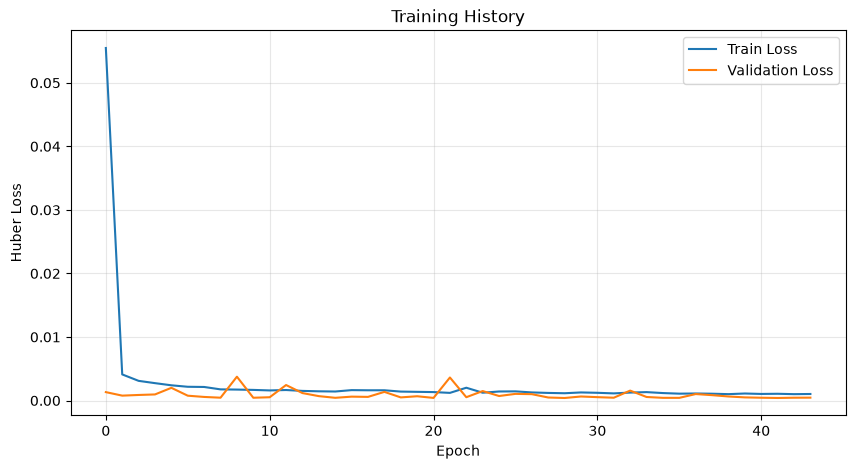

In [27]:
plt.figure(figsize=(10, 5))
plt.plot(train_history, label="Train Loss")
plt.plot(val_history, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Huber Loss")
plt.title("Training History")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [28]:
def predict(model, loader, device):
    model.eval()
    
    preds = []
    trues = []
    
    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(device)
            pred = model(xb)
            preds.append(pred.cpu().numpy())
            trues.append(yb.numpy())
    return np.vstack(preds), np.vstack(trues)

In [29]:
pred_scaled, true_scaled = predict(model, test_loader, DEVICE)

In [30]:
# 모델이 표준화된 값으로 예측한 결과를 원래 KOSPI 종가 단위로 되돌리고, (N, 1) 모양을 (N,)으로 바꿔줌
# ravel(): Numpy 배열을 1차원으로 펴는 함수
pred_close = scaler_y.inverse_transform(pred_scaled).ravel()
true_close = scaler_y.inverse_transform(true_scaled).ravel()
print("예측 개수: ", len(pred_close))
print("예측값 앞 5개: ", np.round(pred_close[:5], 2))
print("실제값 앞 5개: ", np.round(true_close[:5], 2))

예측 개수:  665
예측값 앞 5개:  [2127.   2102.18 2088.81 2085.14 2098.46]
실제값 앞 5개:  [2104.58 2091.   2085.52 2097.38 2096.77]


In [33]:
def regression_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    
    return {
        "MSE": mse,
        "RMSE": rmse,
        "MAE": mae,
        "MAPE(%): ": mape
    }

In [34]:
rnn_metrics = regression_metrics(true_close, pred_close)
for name, value in rnn_metrics.items():
    print(f"{name}: {value:.4f}")

MSE: 6097.4902
RMSE: 78.0864
MAE: 46.2191
MAPE(%): : 1.9736


### Naive Baseline과 비교
주가지수처럼 하루 사이 변화가 상대적으로 작은 데이터에서는 "내일 종가 = 오늘 종가"라고만 예측해도 RMSE/MAE가 꽤 낮게 나올 수 있음. 따라서 RNN의 오차 숫자만 보고 좋은 모델이라고 판단하면 안됨

Navie prediction = 현재 종가

- RNN이 의미 있는 가격 예측 모델이라면 적어도 단순 기준과의 차이를 함께 확인해야 함
- 금융 시계열은 비정상성, 거래비용, 시장 변화 등의 문제가 있으므로 투자 수익 가능성과 동일하게 해석할 수 없음

In [36]:
current_close = data.loc[idx_test, "Close"].to_numpy()
# Navie 예측: 내일 종가 = 오늘 종가
naive_pred = current_close.copy()
naive_metrics = regression_metrics(true_close, naive_pred)
comparison = pd.DataFrame([rnn_metrics, naive_metrics], index=["RNN", "Naive Baseline"])
comparison

,MSE,RMSE,MAE,MAPE(%):
RNN,6097.490234,78.086428,46.219112,1.973557
Naive Baseline,234.087720,15.299925,11.224154,0.535964


### 상승/하락 방향 정확도
- 가격 오차가 작다고 상승/하락 방향까지 잘 맞히는 것은 아님
- 별도로 방향을 비교
    - 실제 변화 = 실제 다음 종가 - 현재 종가
    - 예측 변화 = RNN 예측 종가 - 현재 종가
    - 두 값의 부화가 같으면 방향을 맞힌 것으로 계산

> "Naive prediction = 현재 종가"이면 예측 변화가 항상 0이므로 Naiv의 방향 정확도는 유용한 방향성 기준이 아님

In [ ]:
# RNN이 예측한 가격 변화의 부호와 실제 변화의 부호가 같은지 계산
actual_direction = np.sign(true_close - current_close)
pred_direction = np.sign(pred_close - current_close)
naive_direction = np.sign(naive_pred - current_close)

# 방향성 비교용 baseline: 오늘의 방향이 내일도 이어진다고 가정. 달력 날짜가 아니라 실제 데이터 행 기준 직전 거래일 Close를 사용
prev_close = data.loc[idx_test - 1, "Close"].to_numpy()
prev_direction = np.sign(current_close - prev_close)

direction_accuracy = np.mean(actual_direction == pred_direction) * 100
naive_direction_accuracy = np.mean(actual_direction == naive_direction) * 100
prev_direction_accuracy = np.mean(actual_direction == prev_direction) * 100

print(f"RNN Direction Accuracy          : {direction_accuracy:.2f}%")
print(f"Naive(오늘=내일) Direction Acc. : {naive_direction_accuracy:.2f}%")
print(f"Previous Direction Baseline     : {prev_direction_accuracy:.2f}%")

RNN Direction Accuracy          : 49.92%
Naive(오늘=내일) Direction Acc. : 0.00%
Previous Direction Baseline     : 49.32%


In [39]:
test_dates = pd.to_datetime(data.loc[idx_test, "Target_Date"].to_numpy())

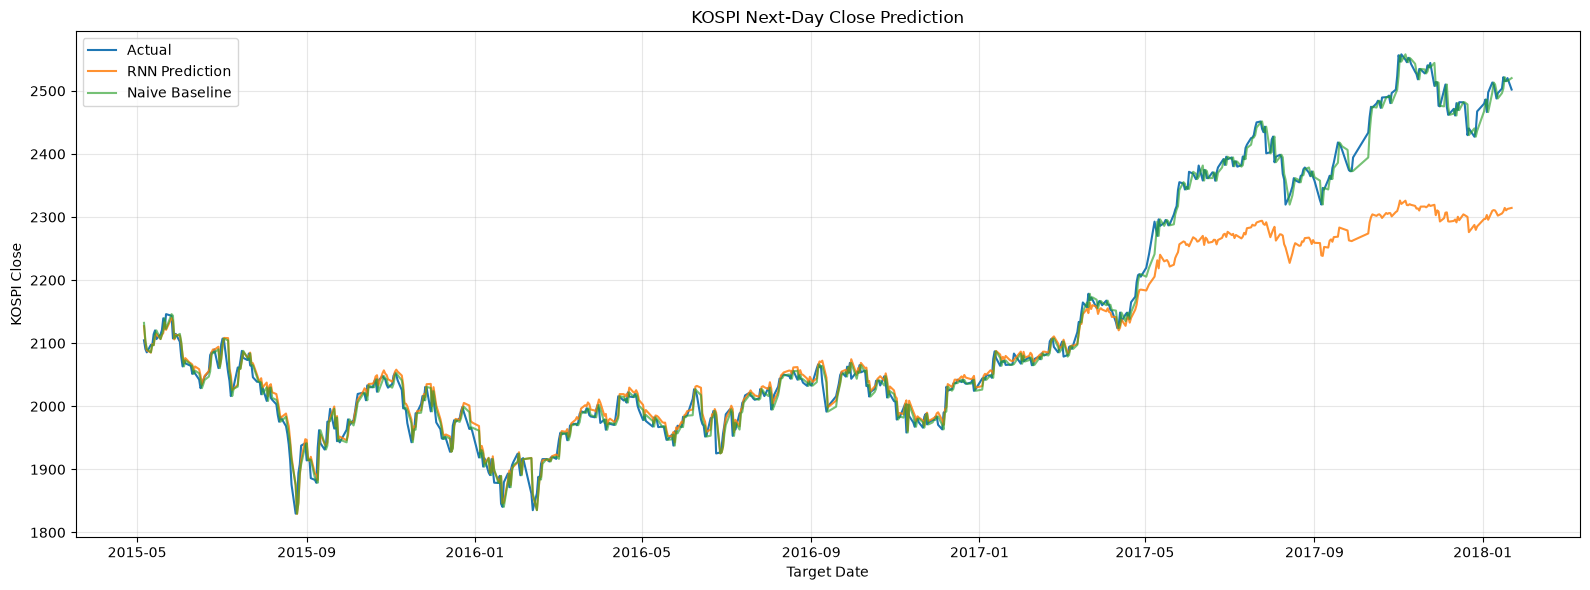

In [40]:
plt.figure(figsize=(16, 6))
plt.plot(test_dates, true_close, label="Actual")
plt.plot(test_dates, pred_close, label="RNN Prediction", alpha=0.85)
plt.plot(test_dates, naive_pred, label="Naive Baseline", alpha=0.65)

plt.title("KOSPI Next-Day Close Prediction")
plt.xlabel("Target Date")
plt.ylabel("KOSPI Close")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

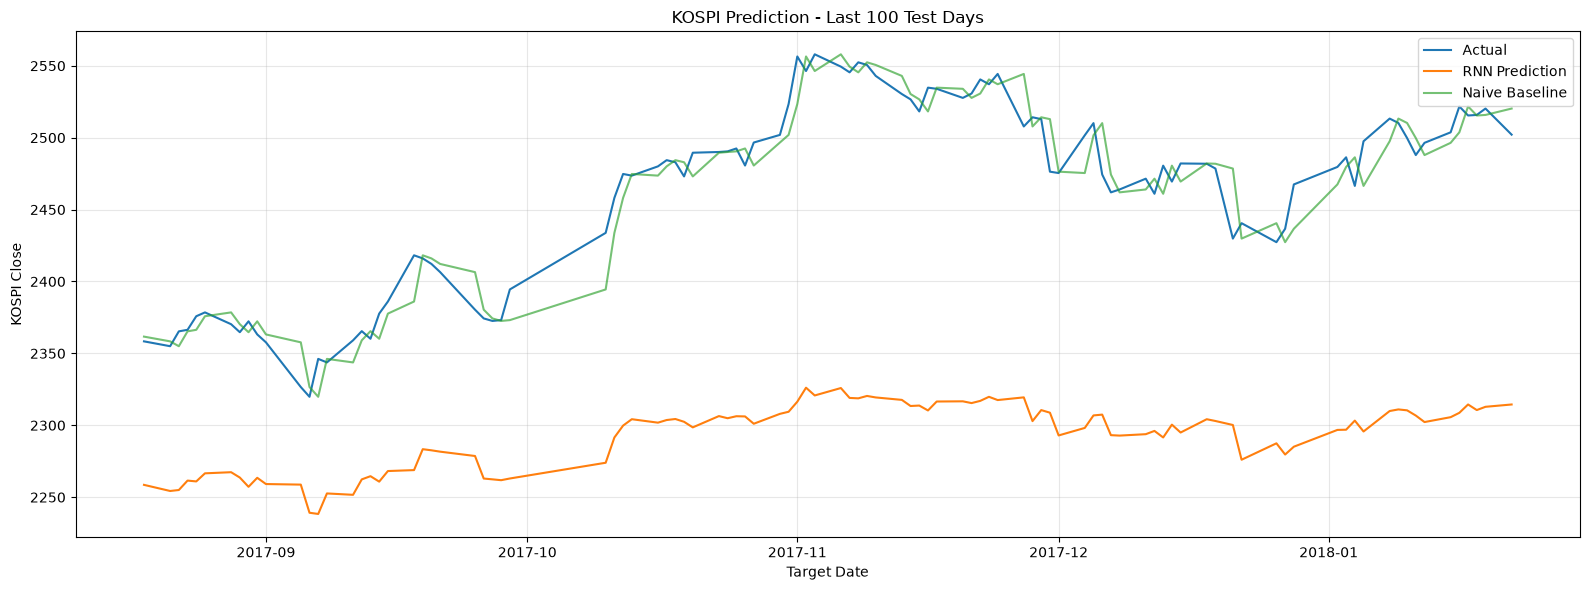

In [41]:
N_VIEW = min(100, len(test_dates))

plt.figure(figsize=(16, 6))

plt.plot(
    test_dates[-N_VIEW:],
    true_close[-N_VIEW:],
    label="Actual"
)

plt.plot(
    test_dates[-N_VIEW:],
    pred_close[-N_VIEW:],
    label="RNN Prediction"
)

plt.plot(
    test_dates[-N_VIEW:],
    naive_pred[-N_VIEW:],
    label="Naive Baseline",
    alpha=0.65
)

plt.title(f"KOSPI Prediction - Last {N_VIEW} Test Days")
plt.xlabel("Target Date")
plt.ylabel("KOSPI Close")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [42]:
result_df = pd.DataFrame({
    "Target_Date": test_dates,
    "Current_Close": current_close,
    "Actual_Next_Close": true_close,
    "RNN_Prediction": pred_close,
    "Naive_Prediction": naive_pred,
})

result_df["RNN_Error"] = (
    result_df["Actual_Next_Close"]
    - result_df["RNN_Prediction"]
)

result_df.tail(20)

,Target_Date,Current_Close,Actual_Next_Close,RNN_Prediction,Naive_Prediction,RNN_Error
645,2017-12-21,2478.530029,2429.830078,2300.216797,2478.530029,129.613281
646,2017-12-22,2429.830078,2440.540039,2276.059082,2429.830078,164.480957
647,2017-12-26,2440.540039,2427.340088,2287.469238,2440.540039,139.870850
648,2017-12-27,2427.340088,2436.669922,2279.676758,2427.340088,156.993164
649,2017-12-28,2436.669922,2467.489990,2285.113281,2436.669922,182.376709
650,2018-01-02,2467.489990,2479.649902,2296.787598,2467.489990,182.862305
651,2018-01-03,2479.649902,2486.350098,2296.937500,2479.649902,189.412598
652,2018-01-04,2486.350098,2466.459961,2303.261719,2486.350098,163.198242
653,2018-01-05,2466.459961,2497.520020,2295.698730,2466.459961,201.821289
654,2018-01-08,2497.520020,2513.280273,2309.926758,2497.520020,203.353516
